# Day 14 — Final 2025 test of return-magnitude forecasts

## 1. Packages and paths

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

PROJECT_ROOT = Path('/Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility')
DATA_DIR = PROJECT_ROOT / 'data'
RESULTS_DIR = PROJECT_ROOT / 'results'
FIGURES_DIR = PROJECT_ROOT / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
file_path = DATA_DIR / 'financial_raw_data.csv'
assert file_path.exists(), f'Missing input: {file_path}'

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

import joblib


## 2. Read the saved specifications and define the same predictors
No test scores are calculated in this section. Features include information through the forecast origin only. Returns and rolling windows are computed on observed S&P dates before dropping missing VIX/yield inputs. No filling of missing values is performed. Forecast time is after the S&P close, VIX close, and yield observation are available. Historical FRED observations are not verified real-time vintages.


In [2]:
required_files = ['day13_configuration.json', 'day13_tuning_summary.csv',
                  'day13_validation_predictions.csv']
for filename in required_files:
    assert (RESULTS_DIR / filename).exists(), f'Missing Day 13 output: {filename}'
config = json.loads((RESULTS_DIR / required_files[0]).read_text(encoding='utf-8'))
tuning = pd.read_csv(RESULTS_DIR / required_files[1]).set_index('method')
assert tuning.index.is_unique
best_params = {name: json.loads(tuning.loc[name, 'best_parameters'])
               for name in ['ridge', 'lasso', 'random_forest']}
day12_features = ['absolute_return', 'mean_abs_5', 'mean_abs_20', 'vix', 'treasury_change']
ml_features = day12_features + ['log_return', 'return_lag_1', 'abs_lag_1', 'abs_lag_5',
                               'squared_return', 'return_std_5', 'return_std_20']
baseline_columns = ['historical_mean', 'ewm_20']
base_columns = ['sp500', 'vix', 'treasury_10yr']
assert config['training_outcomes_end'] == '2022-12-31'
assert config['validation_outcomes'] == ['2023-01-01', '2024-12-31']
assert config['ml_features'] == ml_features and config['day12_features'] == day12_features
assert config['negative_predictions'] == 'Scored unchanged'
display(tuning)


def build_data(until):
    data = pd.read_csv(file_path, parse_dates=['date'])
    assert {'date', 'sp500', 'vix', 'treasury_10yr'}.issubset(data.columns)
    assert data['date'].notna().all(), 'Missing/invalid dates.'
    assert not data['date'].duplicated().any(), 'Duplicate dates.'
    data = data.loc[data['date'] <= pd.Timestamp(until)].sort_values('date').reset_index(drop=True)
    base_columns = ['sp500', 'vix', 'treasury_10yr']
    for col in base_columns:
        data[col] = pd.to_numeric(data[col], errors='raise')
    assert not np.isinf(data[base_columns].to_numpy()).any()
    data = data.dropna(subset=['sp500']).reset_index(drop=True)
    assert data['sp500'].gt(0).all()

    data['log_return'] = 100 * np.log(data['sp500']).diff()
    data['absolute_return'] = data['log_return'].abs()
    data['squared_return'] = data['log_return'] ** 2
    data['return_lag_1'] = data['log_return'].shift(1)
    data['abs_lag_1'] = data['absolute_return'].shift(1)
    data['abs_lag_5'] = data['absolute_return'].shift(5)
    for window in [5, 20]:
        data[f'mean_abs_{window}'] = data['absolute_return'].rolling(window, min_periods=window).mean()
        data[f'return_std_{window}'] = data['log_return'].rolling(window, min_periods=window).std(ddof=1)
    data['treasury_change'] = data['treasury_10yr'].diff()
    data['target_next_day'] = data['absolute_return'].shift(-1)
    data['target_date'] = data['date'].shift(-1)
    data['historical_mean'] = data['absolute_return'].expanding(min_periods=20).mean()
    data['ewm_20'] = data['absolute_return'].ewm(span=20, adjust=False, min_periods=20).mean()

    return data


,mean_fold_RMSE,best_parameters
method,,
ridge,0.711184,"{""model__alpha"": 1000}"
lasso,0.721065,"{""model__alpha"": 0.05}"
random_forest,0.732943,"{""max_depth"": 3, ""max_features"": 0.7, ""min_sam..."


## 3. Reconstruct models using only pre-2023 training outcomes
The saved input fingerprint checks that the pre-2025 S&P sequence and accompanying inputs match Day 13. Hyperparameters come directly from your saved tuning summary. Scaling is fitted on training rows only inside each pipeline. There is no `GridSearchCV` here.

References: [scikit-learn Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).


In [3]:
development = build_data('2024-12-31')
input_bytes = development[['date', *base_columns]].to_csv(index=False).encode('utf-8')
input_hash = hashlib.sha256(input_bytes).hexdigest()
assert input_hash == config['pre2025_sp500_observation_input_sha256'], (
    'Pre-2025 data differ from Day 13. Use the same original saved CSV; do not bypass this check.'
)
cutoff = pd.Timestamp('2022-12-31')
required = ml_features + baseline_columns + ['target_date', 'target_next_day']
usable = development.dropna(subset=required).copy()
train = usable.loc[usable['target_date'] <= cutoff].copy()
validation = usable.loc[usable['target_date'].between('2023-01-01', '2024-12-31')].copy()
day12_train = development.dropna(
    subset=day12_features + baseline_columns + ['target_date', 'target_next_day']
).loc[lambda frame: frame['target_date'] <= cutoff].copy()
assert len(train) == config['ml_training_rows']
assert len(day12_train) == config['day12_training_rows']
assert len(validation) == config['validation_rows']
assert not train.empty and not validation.empty
assert (train['date'] < train['target_date']).all()
assert train['target_date'].max() <= validation['date'].min()
assert np.isfinite(train[ml_features + ['target_next_day']].to_numpy()).all()

def scaled_model(estimator):
    return Pipeline([('scaler', StandardScaler()), ('model', estimator)])

models = {
    'linear_expanded': scaled_model(LinearRegression()),
    'ridge': scaled_model(Ridge()).set_params(**best_params['ridge']),
    'lasso': scaled_model(Lasso(max_iter=50000, tol=1e-5)).set_params(**best_params['lasso']),
    'random_forest': RandomForestRegressor(
        n_estimators=config['random_forest_n_estimators'],
        random_state=config['random_state'], n_jobs=1
    ).set_params(**best_params['random_forest']),
}
for name, model in models.items():
    model.fit(train[ml_features], train['target_next_day'])
day12_reference = LinearRegression().fit(day12_train[day12_features], day12_train['target_next_day'])
methods = baseline_columns + ['day12_extended'] + list(models)

def forecast(frame):
    out = frame[['date', 'target_date', 'target_next_day', *baseline_columns]].copy()
    out['day12_extended'] = day12_reference.predict(frame[day12_features])
    for name, model in models.items():
        out[name] = model.predict(frame[ml_features])
    assert np.isfinite(out[methods + ['target_next_day']].to_numpy()).all()
    return out

print('ML training outcomes:', train['target_date'].min().date(), 'to', train['target_date'].max().date())
print('Training rows:', len(train))


ML training outcomes: 2016-11-01 to 2022-12-30
Training rows: 1528


## 4. Verify validation reproduction and freeze the experiment
Recomputed predictions must match the saved Day 13 predictions before proceeding. If this fails, check the original data, parameters, and package environment; do not loosen the tolerance to proceed. The forest is your prespecified primary candidate from validation, lasso is the simpler competitor, and RMSE is the primary metric; MAE and bias are also reported. All seven methods will still be scored.

The frozen record is saved before test evaluation. Re-running unchanged code is reproducible; changing the experiment after seeing test results makes later results exploratory, not another untouched test.


In [4]:
reproduced = forecast(validation).sort_values('target_date').reset_index(drop=True)
saved = pd.read_csv(RESULTS_DIR / 'day13_validation_predictions.csv',
                    parse_dates=['date', 'target_date']).sort_values('target_date').reset_index(drop=True)
pd.testing.assert_frame_equal(reproduced[['date', 'target_date']], saved[['date', 'target_date']])
np.testing.assert_allclose(reproduced[methods + ['target_next_day']],
                           saved[methods + ['target_next_day']], rtol=1e-8, atol=1e-8,
                           err_msg='Day 13 predictions not reproduced; investigate before testing.')
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit_learn': sklearn.__version__}
frozen = {
    'target': config['target'], 'training_outcomes_end': '2022-12-31',
    'test_outcomes': ['2025-01-01', '2025-12-31'],
    'primary_candidate': 'random_forest', 'simpler_competitor': 'lasso',
    'primary_metric': 'RMSE', 'secondary_metrics': ['MAE', 'Bias'],
    'methods': methods, 'ml_features': ml_features, 'day12_features': day12_features,
    'best_parameters': best_params,
    'random_forest_n_estimators': config['random_forest_n_estimators'],
    'random_state': config['random_state'], 'negative_predictions': 'Scored unchanged',
    'refitting': 'No refit after 2022; observed predictors and baselines update causally',
    'pre2025_input_sha256': input_hash, 'versions': versions,
    'ml_training_rows': len(train), 'day12_training_rows': len(day12_train),
}
frozen_path = RESULTS_DIR / 'day14_frozen_specification.json'
if frozen_path.exists():
    assert json.loads(frozen_path.read_text()) == frozen, (
        'Existing frozen experiment differs. Preserve the original test; investigate changes.'
    )
else:
    frozen_path.write_text(json.dumps(frozen, indent=2), encoding='utf-8')
joblib.dump({'models': models, 'day12_reference': day12_reference, 'specification': frozen},
            RESULTS_DIR / 'day14_frozen_models.joblib')
print('Day 13 validation predictions reproduced. Specification frozen; proceed to 2025.')


Day 13 validation predictions reproduced. Specification frozen; proceed to 2025.


## 5. Prepare 2025 test rows and make forecasts
This is the first test-evaluation step. Build rolling predictors with earlier history included, then split by **outcome date**, allowing late-2024 information to forecast the first 2025 observation. Do not filter to 2025 before building features. Do not shift predictors again.

At each origin, use the observed history through that date. This is sequential one-step forecasting: previous 2025 returns can enter later 2025 predictors and baselines. They are never used to retune or refit the models. Rows with missing required inputs are excluded for every method, and exclusions are recorded. Check that the saved source contains observations through the end of 2025 and all S&P trading observations; the code cannot verify exchange-calendar completeness from this CSV alone.


In [5]:
all_data = build_data('2025-12-31')
assert all_data['date'].max() >= pd.Timestamp('2025-12-31'), (
    'The saved file does not cover year-end 2025. Resolve source coverage before final testing.'
)
candidate_test = all_data.loc[
    all_data['target_date'].between('2025-01-01', '2025-12-31')
].copy()
assert not candidate_test.empty, 'No 2025 test outcomes in the input.'
test = candidate_test.dropna(subset=required).copy()
assert not test.empty, 'No complete shared test rows.'
assert (test['date'] < test['target_date']).all()
assert train['target_date'].max() < test['date'].min()
assert np.isfinite(test[ml_features + baseline_columns + ['target_next_day']].to_numpy()).all()
excluded = candidate_test.loc[~candidate_test.index.isin(test.index), ['date', 'target_date']].copy()
excluded['missing_columns'] = candidate_test.loc[excluded.index, required].apply(
    lambda row: ', '.join(row.index[row.isna()]), axis=1)
predictions = forecast(test)
print('Potential test outcomes:', len(candidate_test))
print('Shared test forecasts:', len(test), '| Excluded:', len(excluded))
print('Outcome dates:', test['target_date'].min().date(), 'to', test['target_date'].max().date())
display(predictions.head())


Potential test outcomes: 250
Shared test forecasts: 246 | Excluded: 4
Outcome dates: 2025-01-02 to 2025-12-31


,date,target_date,target_next_day,historical_mean,ewm_20,day12_extended,linear_expanded,ridge,lasso,random_forest
2074,2024-12-31,2025-01-02,0.222635,0.744023,0.691079,0.669642,0.869269,0.807416,0.764309,0.727811
2075,2025-01-02,2025-01-03,1.251729,0.743772,0.646465,0.685224,0.846973,0.701416,0.694827,0.704790
2076,2025-01-03,2025-01-06,0.552282,0.744017,0.704109,0.597163,0.464010,0.586322,0.557860,0.586723
2077,2025-01-06,2025-01-07,1.116600,0.743924,0.689650,0.588614,0.611580,0.668490,0.657484,0.539816
2078,2025-01-07,2025-01-08,0.155911,0.744104,0.730312,0.611873,0.603950,0.726337,0.663013,0.768205


## 6. Calculate test performance and compare with validation
Lower MAE/RMSE is better. Bias = forecast minus actual: positive is overprediction, negative is underprediction. Errors are in percentage points. Improvement percentages above zero mean lower error than the specified reference. Negative predictions, if any, are scored unchanged. Sorting the final table describes test results; do not change hyperparameters or pick a new rule and present it as independently tested on this same year.


In [6]:
def score_forecasts(frame):
    rows = []
    for name in methods:
        error = frame[name] - frame['target_next_day']
        rows.append({'method': name, 'n_forecasts': len(frame),
                     'MAE': error.abs().mean(), 'RMSE': np.sqrt((error ** 2).mean()),
                     'Bias': error.mean(), 'negative_forecasts': int((frame[name] < 0).sum())})
    scores = pd.DataFrame(rows).set_index('method')
    for reference in ['ewm_20', 'day12_extended']:
        for metric in ['MAE', 'RMSE']:
            denominator = scores.loc[reference, metric]
            assert denominator > 0
            scores[f'{metric}_improvement_vs_{reference}_pct'] = 100 * (1 - scores[metric] / denominator)
    return scores.sort_values('RMSE')

performance = score_forecasts(predictions)
validation_performance = score_forecasts(reproduced)
comparison = pd.concat({'validation_2023_2024': validation_performance,
                        'test_2025': performance}, names=['sample', 'method'])
display(performance.round(4))
display(comparison[['n_forecasts', 'MAE', 'RMSE', 'Bias']].round(4))
print('Prespecified random forest test RMSE:', performance.loc['random_forest', 'RMSE'])
print('Lowest observed test RMSE:', performance['RMSE'].idxmin())
print('Lowest observed test MAE:', performance['MAE'].idxmin())


,n_forecasts,MAE,RMSE,Bias,negative_forecasts,MAE_improvement_vs_ewm_20_pct,RMSE_improvement_vs_ewm_20_pct,MAE_improvement_vs_day12_extended_pct,RMSE_improvement_vs_day12_extended_pct
method,,,,,,,,,
day12_extended,246,0.4920,0.8088,0.0205,0,4.5237,7.2207,0.0000,0.0000
lasso,246,0.4930,0.8371,0.0202,0,4.3257,3.9699,-0.2074,-3.5038
random_forest,246,0.5028,0.8526,0.0202,0,2.4317,2.1970,-2.1912,-5.4147
linear_expanded,246,0.5036,0.8565,0.0397,0,2.2823,1.7425,-2.3477,-5.9045
ridge,246,0.5019,0.8580,0.0253,0,2.6155,1.5745,-1.9987,-6.0855
ewm_20,246,0.5153,0.8717,0.0076,0,0.0000,0.0000,-4.7381,-7.7826
historical_mean,246,0.5463,0.9198,0.0128,0,-5.9996,-5.5125,-11.0220,-13.7241


n_forecasts     MAE    RMSE    Bias
sample               method                                              
validation_2023_2024 random_forest            496  0.4065  0.5180 -0.0416
                     lasso                    496  0.4127  0.5182 -0.0113
                     ridge                    496  0.4189  0.5218  0.0165
                     day12_extended           496  0.4153  0.5261 -0.0325
                     linear_expanded          496  0.4159  0.5281 -0.0332
                     ewm_20                   496  0.4229  0.5301  0.0037
                     historical_mean          496  0.4591  0.5471  0.1425
test_2025            day12_extended           246  0.4920  0.8088  0.0205
                     lasso                    246  0.4930  0.8371  0.0202
                     random_forest            246  0.5028  0.8526  0.0202
                     linear_expanded          246  0.5036  0.8565  0.0397
                     ridge                    246  0.5019  0.8580  0.0253
                     ewm_20                   246  0.5153  0.8717  0.0076
                     historical_mean          246  0.5463  0.9198  0.0128

Prespecified random forest test RMSE: 0.8525604664700994
Lowest observed test RMSE: day12_extended
Lowest observed test MAE: day12_extended


## 7. Plot and save outputs
These plots show the realized magnitude, not a directly observed latent volatility. The two forest/lasso panels keep the simpler competitor visible alongside the primary candidate. No earlier result files are overwritten.


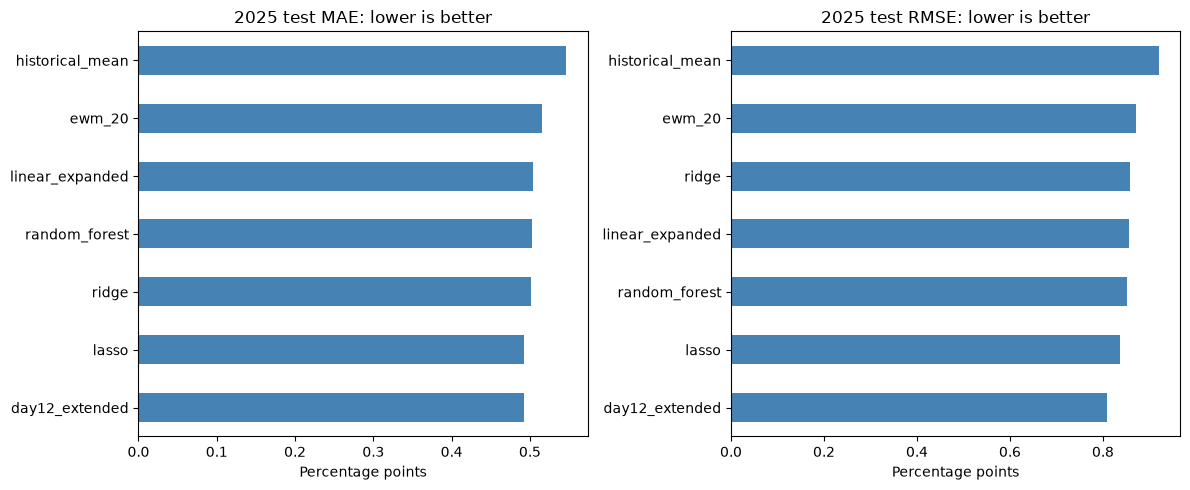

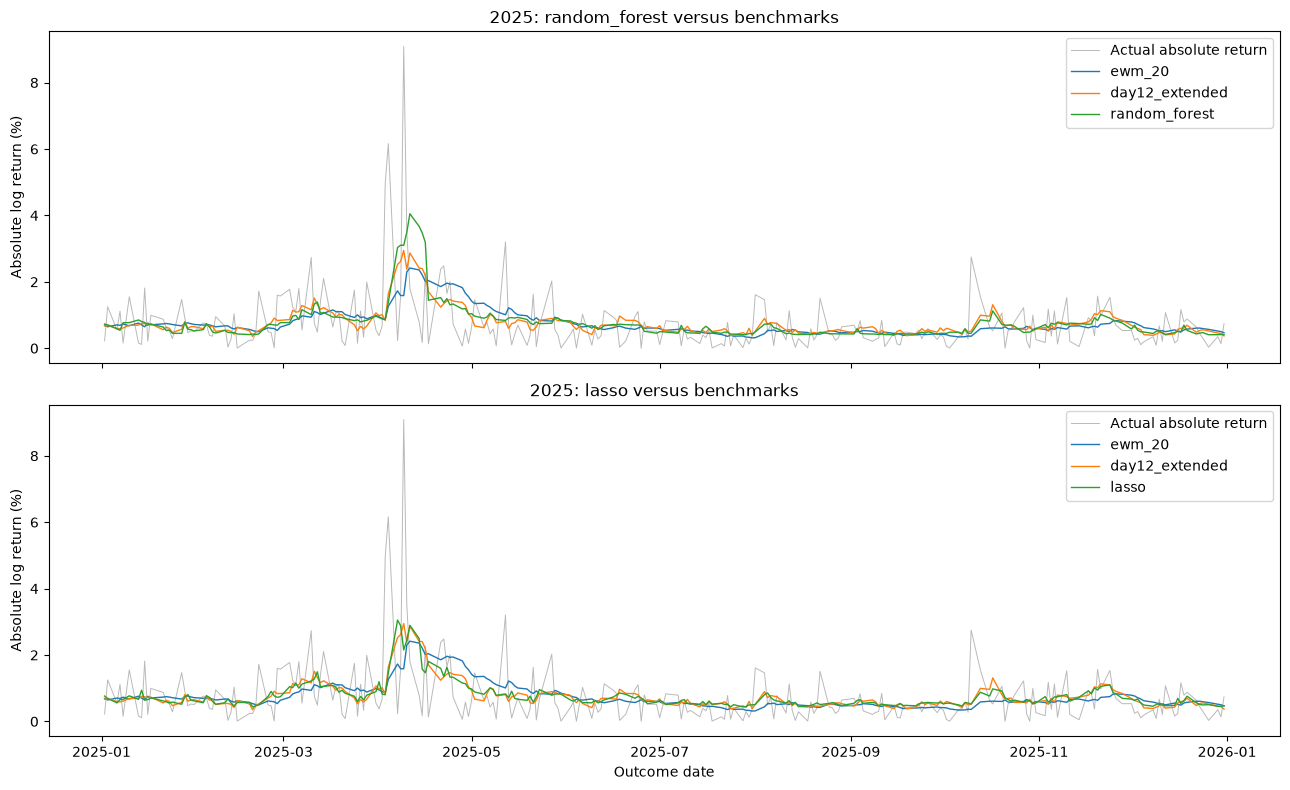

Saved Day 14 results to: /Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility/results
Saved Day 14 figures to: /Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility/figures


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    performance[metric].sort_values().plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'2025 test {metric}: lower is better')
    ax.set_xlabel('Percentage points')
    ax.set_ylabel('')
save_figure(fig, 'day14_test_model_comparison.png')

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, candidate in zip(axes, ['random_forest', 'lasso']):
    ax.plot(predictions['target_date'], predictions['target_next_day'],
            color='gray', alpha=0.55, linewidth=0.7, label='Actual absolute return')
    for name in ['ewm_20', 'day12_extended', candidate]:
        ax.plot(predictions['target_date'], predictions[name], linewidth=1, label=name)
    ax.set_title(f'2025: {candidate} versus benchmarks')
    ax.set_ylabel('Absolute log return (%)')
    ax.legend()
axes[-1].set_xlabel('Outcome date')
save_figure(fig, 'day14_test_forecasts.png')

predictions.to_csv(RESULTS_DIR / 'day14_test_predictions.csv', index=False)
performance.to_csv(RESULTS_DIR / 'day14_test_performance.csv')
comparison.to_csv(RESULTS_DIR / 'day14_validation_test_comparison.csv')
excluded.to_csv(RESULTS_DIR / 'day14_excluded_test_dates.csv', index=False)
run_record = {'frozen_specification': frozen, 'test_rows': len(test),
              'potential_test_rows': len(candidate_test), 'excluded_rows': len(excluded),
              'test_outcome_first': str(test['target_date'].min().date()),
              'test_outcome_last': str(test['target_date'].max().date()),
              'raw_file_sha256': hashlib.sha256(file_path.read_bytes()).hexdigest()}
(RESULTS_DIR / 'day14_run_record.json').write_text(json.dumps(run_record, indent=2), encoding='utf-8')
print('Saved Day 14 results to:', RESULTS_DIR)
print('Saved Day 14 figures to:', FIGURES_DIR)


**Your Day 12 extended regression performed best on the 2025 test set. Random forest’s validation lead did not persist, although it still beat EWM.**

All seven methods used **246 shared forecast dates**, from **January 2–December 31, 2025**. Four of the 250 potential outcomes were excluded for missing inputs. Errors are in **percentage points**.

| Method | Test MAE | Test RMSE | Bias |
|---|---:|---:|---:|
| **Day 12 extended regression** | **0.4920** | **0.8088** | 0.0205 |
| Lasso | 0.4930 | 0.8371 | 0.0202 |
| Random forest | 0.5028 | 0.8526 | 0.0202 |
| Expanded linear regression | 0.5036 | 0.8565 | 0.0397 |
| Ridge | 0.5019 | 0.8580 | 0.0253 |
| EWM | 0.5153 | 0.8717 | **0.0076** |
| Historical mean | 0.5463 | 0.9198 | 0.0128 |

The main findings are:

1. **The extended regression had the strongest observed test performance.** It reduced MAE by approximately **4.52%** and RMSE by **7.22%** relative to EWM. Your original predictor set therefore remained competitive against the more complex models.

2. **Lasso was the strongest machine-learning alternative.** Its MAE was almost identical to the extended regression’s, but its RMSE was **3.50% higher**. It also outperformed random forest on both metrics.

3. **Random forest retained a modest advantage over EWM.** It reduced test MAE by **2.43%** and RMSE by **2.20%**. However, its RMSE was **5.41% higher** than the extended regression’s. The evidence supports improvement over EWM in this year, rather than consistent superiority over simpler regression.

4. **EWM remained best calibrated on average.** Its bias was closest to zero. Every method slightly overpredicted on average, and **none produced negative test forecasts**. Small average bias can coexist with substantial individual errors.

Your plots show particularly large realized movements around **April 2025** that all displayed methods missed. The forest then produced a more pronounced period of elevated forecasts. The higher test RMSEs are consistent with larger extreme errors in 2025; they do not alone establish overfitting.

**Your project’s conclusion is that additional complexity did not consistently improve forecasting:** forest led during validation, while the simpler extended regression led during final testing. These rankings remain descriptive because uncertainty in the paired forecast-error differences has not yet been quantified.

Once your outputs and interpretation are saved, **Day 14 is complete**. Preserve these results: **2025 has now been used for testing**, so changes inspired by them need fresh independent evaluation data.
